<a href="https://colab.research.google.com/github/trsantanarural/predicao-falhas-tarefas/blob/main/notebooks/05_classificacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05. Classificação: Random Forest e XGBoost

**Entradas:** `saida/base_modelagem.parquet` (notebook 02) e `saida/base_conjuntos.parquet` (notebook 04)
**Saídas:** `saida/classificacao_*.csv`, `saida/classificacao_predicoes_teste.parquet` e figuras em `figuras/`

Este notebook:
1. usa a divisão por job do notebook 04: treino (dias 1 a 19), validação (dias 20 a 23) e teste (dias 24 a 29);
2. prepara os atributos (imputação pela mediana do treino com indicador de ausência, `log(1 + x)` nas métricas de consumo e padronização, ajustadas só nos dados de ajuste);
3. busca hiperparâmetros do Random Forest e do XGBoost na validação e escolhe o limiar de decisão na validação;
4. reajusta cada modelo nos dias 1 a 23 e avalia no teste, com todos os jobs e sem o job que concentra mais falhas do conjunto;
5. repete o procedimento em três variantes de atributos (com tempo observado, com filtro de Pearson e as duas juntas) e em uma extensão com atributos de contexto;
6. mostra as matrizes de confusão do modelo principal no teste;
7. explica o modelo de melhor desempenho na validação com valores SHAP.

**Decisões fixadas antes de olhar o teste**
- Desbalanceamento: `class_weight='balanced'` no Random Forest e `scale_pos_weight` (negativas/positivas) no XGBoost, combinados a um peso por tarefa igual ao inverso do tamanho do job (normalizado para média 1 em cada ajuste).
- Critério de escolha dos hiperparâmetros: PR-AUC na validação ponderada por job. Limiar de decisão: o que maximiza o F1 da classe de falha na validação, também com peso por job. Isso evita que um único job com milhares de tarefas, como o da validação, decida a escolha.
- O limiar vem do modelo ajustado nos dias 1 a 19 e é aplicado ao modelo reajustado nos dias 1 a 23; as probabilidades dos dois modelos não são idênticas, e essa diferença não é corrigida.
- Checkpoints: a busca de hiperparâmetros (por configuração) e cada combinação de variante e algoritmo gravam seu resultado em `saida/classificacao_ckpt`. Se a sessão cair, execute de novo a partir da seção 1 (com `RETOMAR = True`) e as etapas concluídas são lidas do disco; se os dados ou os parâmetros mudarem, a etapa é recalculada. Para forçar tudo de novo, use `RETOMAR = False`.
- As métricas de teste são reportadas com a proporção original de classes (sem pesos), por tarefa, e também por job (recall médio entre os jobs com falha).

## 1. Configuração do ambiente

In [29]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, time, json, hashlib, subprocess, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_fscore_support,
                             confusion_matrix, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'], check=True)
    import shap
warnings.filterwarnings('ignore', category=FutureWarning)

# Pasta de trabalho no Google Drive (base do notebook 02, conjuntos do notebook 04, saídas e figuras)
BASE = '/content/drive/MyDrive/artigo_predicao'
FIG = f'{BASE}/figuras'
SAIDA = f'{BASE}/saida'
os.makedirs(FIG, exist_ok=True)

SEED = 42
KEY = ['job_id', 'task_index']
H = 600_000_000                     # horizonte de 10 minutos, em microssegundos

# Atributos (conjunto de Santos, 2023, sem os tempos de disco e, no modelo principal, sem a duração)
SUBMISSAO = ['priority', 'cpu_req', 'ram_req', 'disk_req']
CONSUMO = ['cpu_rate', 'canonical_mem', 'assigned_mem', 'unmapped_cache', 'total_cache',
           'disk_space', 'cpi', 'mai', 'sampled_cpu', 'max_mem', 'max_cpu']
DURACAO = ['tempo_obs', 'n_janelas']          # só entram na variante de comparação
PRINCIPAL = SUBMISSAO + CONSUMO
NOMES = {'priority': 'Prioridade', 'scheduling_class': 'Classe de escalonamento',
         'cpu_req': 'CPU solicitada', 'ram_req': 'Memória solicitada', 'disk_req': 'Disco solicitado',
         'cpu_rate': 'CPU média', 'canonical_mem': 'Memória canônica', 'assigned_mem': 'Memória atribuída',
         'unmapped_cache': 'Cache não mapeado', 'total_cache': 'Cache total', 'disk_space': 'Espaço em disco',
         'cpi': 'Ciclos por instrução', 'mai': 'Acessos à memória por instrução',
         'sampled_cpu': 'Amostra de CPU', 'max_mem': 'Memória máxima', 'max_cpu': 'CPU máxima',
         'tempo_obs': 'Tempo observado', 'n_janelas': 'Nº de janelas',
         'cpi_ausente': 'CPI ausente', 'mai_ausente': 'MAI ausente', 'atraso_sched_ausente': 'Atraso ausente',
         'hora_sin': 'Hora do dia (seno)', 'hora_cos': 'Hora do dia (cosseno)',
         'dsem_sin': 'Dia da semana (seno)', 'dsem_cos': 'Dia da semana (cosseno)',
         'atraso_sched': 'Atraso de escalonamento'}

# Controles de custo e de extensão (ajuste antes de executar)
N_ITER_RF = 6              # configurações sorteadas na busca do Random Forest
N_ITER_XGB = 10            # configurações sorteadas na busca do XGBoost
AMOSTRA_SHAP = 2000        # tarefas do teste explicadas pelo SHAP
EXTRAIR_ATRASO = False     # True: lê de novo task_events (500 arquivos) para o atraso de escalonamento
RETOMAR = True             # True: reaproveita os checkpoints de saida/classificacao_ckpt (False: recalcula tudo)
N_ARQ = 500                # arquivos de task_events (só altere em testes)

AZUL, LARANJA = '#2a78d6', '#eb6834'
TXT, TXT2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'font.size': 10, 'axes.edgecolor': TXT2, 'axes.labelcolor': TXT, 'xtick.color': TXT2,
    'ytick.color': TXT2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.bbox': 'tight'})


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Dados e conjuntos
Lê a base de modelagem e o conjunto de cada tarefa (divisão por job, notebook 04) e calcula o peso por job. Os tamanhos devem coincidir com os do notebook 04 (treino 485.308, validação 104.308 e teste 134.733 tarefas). O "job dominante" de cada conjunto é o de maior número de falhas.

In [30]:
base = pd.read_parquet(f'{SAIDA}/base_modelagem.parquet')
conj = pd.read_parquet(f'{SAIDA}/base_conjuntos.parquet')[KEY + ['dia_job', 'conjunto']]
base = base.merge(conj, on=KEY, how='inner', validate='one_to_one')
assert len(base) == len(conj), 'base_conjuntos.parquet não corresponde a base_modelagem.parquet (rode o notebook 04)'

# Peso por tarefa: inverso do número de tarefas do job na base de modelagem (igual ao notebook 04)
base['peso'] = 1.0 / base.job_id.map(base.groupby('job_id').size())

TR = (base.conjunto == 'treino').to_numpy()
VA = (base.conjunto == 'validação').to_numpy()
TE = (base.conjunto == 'teste').to_numpy()

resumo = base.groupby('conjunto').falha.agg(tarefas='size', falhas='sum', taxa='mean')
resumo['jobs'] = base.groupby('conjunto').job_id.nunique()
print(resumo.reindex(['treino', 'validação', 'teste']).round(4).to_string())

# Job com mais falhas de cada conjunto (nome do job dominante usado nos recortes de avaliação)
falhas_job = base.groupby(['conjunto', 'job_id']).falha.sum()
DOM = {c: int(falhas_job.loc[c].idxmax()) for c in ['treino', 'validação', 'teste']}
for c, j in DOM.items():
    n = int((base.job_id == j).sum()); f = int(base.loc[base.job_id == j, 'falha'].sum())
    print(f'job dominante do {c}: {j} ({n} tarefas, {f} falhas)')

# Verificações
print('conjuntos disjuntos por job:', base.groupby('job_id').conjunto.nunique().max() == 1)
print('valores ausentes nos atributos:', base[PRINCIPAL + DURACAO].isna().sum()[lambda s: s > 0].to_dict())

# Checkpoints: cada etapa demorada grava seu resultado e, se a sessão cair, basta rodar de novo
# (com RETOMAR = True) que as etapas concluídas são lidas do disco. Cada checkpoint leva uma
# assinatura dos dados e dos parâmetros; se algo mudou, a etapa é recalculada.
CK = f'{SAIDA}/classificacao_ckpt'
os.makedirs(CK, exist_ok=True)
def assinatura(*partes):
    return hashlib.md5(json.dumps(partes, sort_keys=True, default=str).encode()).hexdigest()
SIG_BASE = assinatura(len(base), int(base.falha.sum()), SEED)


           tarefas  falhas    taxa  jobs
conjunto                                
treino      485308   30164  0.0622  5415
validação   104308    6823  0.0654  1282
teste       134733    9058  0.0672  1697
job dominante do treino: 6337545460 (19579 tarefas, 19579 falhas)
job dominante do validação: 6418746280 (3115 tarefas, 3115 falhas)
job dominante do teste: 6449919400 (6655 tarefas, 6655 falhas)
conjuntos disjuntos por job: True
valores ausentes nos atributos: {'cpi': 125817, 'mai': 143203}


## 3. Preparação dos atributos e variantes
O modelo principal usa o conjunto de atributos de Santos (2023) sem os tempos de disco e sem a duração: prioridade, CPU, memória e disco solicitados e as 11 métricas de consumo. O tempo observado e o número de janelas carregam a duração total da tarefa (o corte do horizonte é ancorado no término) e só entram na variante de comparação.

O filtro de Pearson segue Santos (2023): limiar de 0,8 em módulo, calculado no treino (dias 1 a 19), com valores originais e observações completas par a par. Em cada par acima do limiar mantém-se a variável de menor correlação média absoluta com as demais, regra que Santos (2023) não descreve. Há duas versões: sobre o conjunto principal e sobre o conjunto com o tempo observado (a mais próxima do Experimento 3 de Santos).

In [31]:
class Prep:
    """Imputação pela mediana (com indicador de ausência), log(1 + x) nas métricas de consumo e
    padronização, tudo ajustado só nos dados de ajuste."""
    def __init__(self, colunas):
        self.colunas = list(colunas)
        self.log = [c for c in self.colunas if c in CONSUMO]

    def _bruto(self, d):
        x = d[self.colunas].astype('float64').copy()
        for c in self.na:
            x[c + '_ausente'] = x[c].isna().astype('float64')
            x[c] = x[c].fillna(self.med[c])
        for c in self.log:
            x[c] = np.log1p(x[c])
        return x

    def fit(self, d):
        x = d[self.colunas].astype('float64')
        self.na = [c for c in self.colunas if c in ('cpi', 'mai', 'atraso_sched')]   # atributos com valores ausentes
        self.med = x[self.na].median()
        self.escala = StandardScaler().fit(self._bruto(d))
        return self

    def transform(self, d):
        b = self._bruto(d)
        return pd.DataFrame(self.escala.transform(b), columns=b.columns, index=d.index)


def filtro_pearson(d, colunas, limiar=0.8):
    """Filtro de correlação de Pearson, em valores originais e com observações completas par a par.
    Em cada par com |r| > limiar, mantém-se a variável de menor correlação média absoluta com as demais."""
    corr = d[colunas].corr(method='pearson').abs()
    media = (corr.sum() - 1) / (len(colunas) - 1)
    pares = sorted(((a, b, corr.loc[a, b]) for i, a in enumerate(colunas) for b in colunas[i + 1:]
                    if corr.loc[a, b] > limiar), key=lambda t: -t[2])
    removidas = []
    for a, b, r in pares:
        if a in removidas or b in removidas:
            continue
        removidas.append(a if media[a] > media[b] else b)
    return [c for c in colunas if c not in removidas], removidas, pares


# Variantes de atributos
mantidas_p, removidas_p, pares_p = filtro_pearson(base[TR], PRINCIPAL)
mantidas_tp, removidas_tp, pares_tp = filtro_pearson(base[TR], PRINCIPAL + DURACAO)
VARIANTES = {'principal': PRINCIPAL,
             'com tempo observado': PRINCIPAL + DURACAO,
             'filtro de Pearson': mantidas_p,
             'tempo observado + filtro de Pearson': mantidas_tp}
print('Pearson sobre o conjunto principal | pares com |r| > 0,8:', [(a, b, round(float(r), 3)) for a, b, r in pares_p])
print('  removidas:', removidas_p)
print('Pearson com tempo observado | pares com |r| > 0,8:', [(a, b, round(float(r), 3)) for a, b, r in pares_tp])
print('  removidas:', removidas_tp)


Pearson sobre o conjunto principal | pares com |r| > 0,8: [('canonical_mem', 'assigned_mem', 0.993), ('cpi', 'mai', 0.968), ('cpu_rate', 'sampled_cpu', 0.945), ('assigned_mem', 'max_mem', 0.907), ('canonical_mem', 'max_mem', 0.905)]
  removidas: ['assigned_mem', 'mai', 'cpu_rate', 'canonical_mem']
Pearson com tempo observado | pares com |r| > 0,8: [('tempo_obs', 'n_janelas', 0.999), ('canonical_mem', 'assigned_mem', 0.993), ('cpi', 'mai', 0.968), ('cpu_rate', 'sampled_cpu', 0.945), ('assigned_mem', 'max_mem', 0.907), ('canonical_mem', 'max_mem', 0.905)]
  removidas: ['n_janelas', 'assigned_mem', 'mai', 'cpu_rate', 'canonical_mem']


## 4. Busca de hiperparâmetros na validação
Treina nos dias 1 a 19 e avalia nos dias 20 a 23, com configurações sorteadas de um espaço fixo (sementes fixas). Random Forest: número de árvores, profundidade máxima, mínimo de amostras por folha e `max_features`. XGBoost: número de árvores, profundidade máxima, taxa de aprendizado, `subsample`, `colsample_bytree` e `min_child_weight`. As configurações escolhidas valem para todas as variantes.

In [32]:
def ajusta(algo, params, X, y, w):
    """Ajusta o modelo com ponderação por classe e peso por job (normalizado para média 1,
    para que min_child_weight e afins do XGBoost mantenham o significado)."""
    w = np.asarray(w, dtype='float64'); w = w / w.mean()
    if algo == 'RF':
        m = RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=SEED, **params)
    else:
        spw = float((y == 0).sum() / (y == 1).sum())
        m = XGBClassifier(tree_method='hist', scale_pos_weight=spw, eval_metric='aucpr',
                          n_jobs=-1, random_state=SEED, **params)
    return m.fit(X, y, sample_weight=w)

ESPACO = {'RF': {'n_estimators': [300], 'max_depth': [8, 12, 16, 24], 'min_samples_leaf': [5, 20, 50],
                 'max_features': ['sqrt', 0.5]},
          'XGBoost': {'n_estimators': [200, 400], 'max_depth': [3, 5, 7], 'learning_rate': [0.03, 0.1],
                      'subsample': [0.8, 1.0], 'colsample_bytree': [0.8, 1.0], 'min_child_weight': [1, 5]}}
N_ITER = {'RF': N_ITER_RF, 'XGBoost': N_ITER_XGB}

# Busca na validação temporal: treina nos dias 1 a 19 (conjunto de treino) e avalia nos dias 20 a 23.
# Critério: PR-AUC ponderada por job, para que um único job com milhares de tarefas não decida a escolha.
pre_a = Prep(PRINCIPAL).fit(base[TR])
Xa, ya, wa = pre_a.transform(base[TR]), base.falha[TR].to_numpy(), base.peso[TR].to_numpy()
Xv, yv, wv = pre_a.transform(base[VA]), base.falha[VA].to_numpy(), base.peso[VA].to_numpy()

busca, MELHOR, CAND = [], {}, {'RF': [], 'XGBoost': []}
arq_busca = f'{CK}/busca.json'
sig_busca = assinatura(SIG_BASE, ESPACO, N_ITER, PRINCIPAL)
feitos = json.load(open(arq_busca)) if RETOMAR and os.path.exists(arq_busca) else {}
if feitos.get('sig') != sig_busca:
    feitos = {'sig': sig_busca, 'res': {}}
for algo in ('RF', 'XGBoost'):
    n = min(N_ITER[algo], int(np.prod([len(v) for v in ESPACO[algo].values()])))
    for params in ParameterSampler(ESPACO[algo], n_iter=n, random_state=SEED):
        chave = algo + json.dumps(params, sort_keys=True, default=str)
        if chave in feitos['res']:
            r = feitos['res'][chave]
            print(algo, params, round(r['PR-AUC ponderada por job (validação)'], 4), '(retomado)')
        else:
            t0 = time.time()
            m = ajusta(algo, params, Xa, ya, wa)
            p = m.predict_proba(Xv)[:, 1]
            r = {'PR-AUC ponderada por job (validação)': average_precision_score(yv, p, sample_weight=wv),
                 'PR-AUC (validação)': average_precision_score(yv, p),
                 'ROC-AUC (validação)': roc_auc_score(yv, p), 'segundos': round(time.time() - t0)}
            feitos['res'][chave] = r
            json.dump(feitos, open(arq_busca + '.tmp', 'w')); os.replace(arq_busca + '.tmp', arq_busca)
            print(algo, params, round(r['PR-AUC ponderada por job (validação)'], 4), f'{time.time() - t0:.0f}s')
        CAND[algo].append((r['PR-AUC ponderada por job (validação)'], dict(params)))
        busca.append({'algoritmo': algo, **params, **r})
busca = pd.DataFrame(busca)
for algo in ('RF', 'XGBoost'):
    MELHOR[algo] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in max(CAND[algo], key=lambda t: t[0])[1].items()}
    print(f'\n{algo}: melhor configuração', MELHOR[algo])
busca.round(4).to_csv(f'{SAIDA}/classificacao_busca_hiperparametros.csv', index=False)


RF {'n_estimators': 300, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 12} 0.6615 (retomado)
RF {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 16} 0.6223 (retomado)
RF {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8} 0.6823 (retomado)
RF {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 24} 0.6483 (retomado)
RF {'n_estimators': 300, 'min_samples_leaf': 50, 'max_features': 0.5, 'max_depth': 12} 0.5922 (retomado)
RF {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 12} 0.6536 (retomado)
XGBoost {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0} 0.6552 (retomado)
XGBoost {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 1.0} 0.6629 (retomado)
XGBoost {'subsample': 1.0, 'n_estimators': 200, 'min_child_we

## 5. Treino final, limiar e avaliação
Para cada variante e algoritmo: (A) ajusta nos dias 1 a 19 e escolhe o limiar de decisão na validação; (B) reajusta nos dias 1 a 23 com a mesma configuração e avalia no teste com esse limiar. As métricas do "treino (dias 1 a 23)" servem à comparação com o teste (indício de overfitting). As linhas "sem os jobs dominantes" retiram o job com mais falhas de cada conjunto (do treino e da validação, no treino final).

In [33]:
def limiar_otimo(y, p, w):
    """Limiar que maximiza o F1 da classe de falha na validação, com peso por job."""
    pr, rc, th = precision_recall_curve(y, p, sample_weight=w)
    f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12)
    return float(th[int(np.argmax(f1))])

def metricas(y, p, lim):
    pred = (p >= lim).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    r = {'tarefas': len(y), 'falhas': int(y.sum()), 'taxa de falha': y.mean(),
         'precisão (falha)': pr[1], 'recall (falha)': rc[1], 'F1 (falha)': f1[1],
         'precisão (concluída)': pr[0], 'recall (concluída)': rc[0], 'F1 (concluída)': f1[0],
         'precisão (média)': pr.mean(), 'recall (média)': rc.mean(), 'F1 (média)': f1.mean(),
         'acurácia': (tp + tn) / len(y), 'taxa de falsos positivos': fp / (fp + tn) if fp + tn else np.nan,
         'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp, 'limiar': lim}
    ok = 0 < y.sum() < len(y)
    r['ROC-AUC'] = roc_auc_score(y, p) if ok else np.nan
    r['PR-AUC'] = average_precision_score(y, p) if ok else np.nan
    return r

def recall_por_job(d, p, lim):
    """Recall médio entre os jobs que têm ao menos uma falha (cada job conta uma vez)."""
    t = pd.DataFrame({'job': d.job_id.to_numpy(), 'y': d.falha.to_numpy(), 'pred': (p >= lim).astype(int)})
    t = t[t.y == 1]
    return t.groupby('job').pred.mean().mean() if len(t) else np.nan

def linhas(variante, algo, conjunto, d, p, lim, excluir=()):
    out = []
    for recorte, m in (('todos os jobs', np.ones(len(d), bool)),
                       ('sem os jobs dominantes', ~d.job_id.isin(excluir).to_numpy())):
        if recorte != 'todos os jobs' and not len(excluir):
            continue
        y = d.falha.to_numpy()[m]
        r = {'variante': variante, 'algoritmo': algo, 'conjunto': conjunto, 'recorte': recorte}
        r.update(metricas(y, p[m], lim))
        r['recall médio por job'] = recall_por_job(d[m], p[m], lim)
        out.append(r)
    return out

# Quando o conjunto de ajuste é treino + validação, o "treino" inclui os jobs dominantes dos dois
EXCL = {'validação': [DOM['validação']], 'teste': [DOM['teste']],
        'treino (dias 1 a 23)': [DOM['treino'], DOM['validação']]}
PRB, MODELOS, LIMIARES, LINHAS, SCORE_VAL = {}, {}, [], [], {}
TRVA = TR | VA

def avalia_um(variante, colunas, algo):
    """(A) ajusta nos dias 1 a 19 e escolhe o limiar na validação (dias 20 a 23);
    (B) reajusta nos dias 1 a 23 com a mesma configuração e avalia no teste com esse limiar.
    O resultado fica em checkpoint (o modelo só é guardado na variante principal, para o SHAP)."""
    nome = variante.replace(' ', '_').replace('+', 'mais')
    arq = f'{CK}/{nome}__{algo}.joblib'
    sig = assinatura(SIG_BASE, variante, list(colunas), algo, MELHOR[algo])
    if RETOMAR and os.path.exists(arq):
        try:
            d = joblib.load(arq)
        except Exception:  # arquivo truncado (sessão caiu durante a gravação): refaz
            d = {'sig': None}
        if d['sig'] == sig:
            LINHAS.extend(d['linhas']); LIMIARES.append(d['limiar'])
            SCORE_VAL[(variante, algo)] = d['score']; PRB[(variante, algo)] = d['prb']
            if d['modelo'] is not None:
                MODELOS[(variante, algo)] = d['modelo']
            print(f'{variante} | {algo}: retomado do checkpoint')
            return
    t0 = time.time()
    linhas_loc = []
    # A: treino -> validação
    pre = Prep(colunas).fit(base[TR])
    m = ajusta(algo, MELHOR[algo], pre.transform(base[TR]), base.falha[TR].to_numpy(), base.peso[TR].to_numpy())
    dv = base[VA]; pv = m.predict_proba(pre.transform(dv))[:, 1]
    lim = limiar_otimo(dv.falha.to_numpy(), pv, dv.peso.to_numpy())
    score = average_precision_score(dv.falha.to_numpy(), pv, sample_weight=dv.peso.to_numpy())
    linhas_loc += linhas(variante, algo, 'validação', dv, pv, lim, EXCL['validação'])
    # B: treino + validação -> teste
    pre = Prep(colunas).fit(base[TRVA])
    db, dt = base[TRVA], base[TE]
    m = ajusta(algo, MELHOR[algo], pre.transform(db), db.falha.to_numpy(), db.peso.to_numpy())
    pb, pt = m.predict_proba(pre.transform(db))[:, 1], m.predict_proba(pre.transform(dt))[:, 1]
    linhas_loc += linhas(variante, algo, 'treino (dias 1 a 23)', db, pb, lim, EXCL['treino (dias 1 a 23)'])
    linhas_loc += linhas(variante, algo, 'teste', dt, pt, lim, EXCL['teste'])
    limiar_loc = {'variante': variante, 'algoritmo': algo, 'limiar': lim, 'PR-AUC ponderada por job (validação)': score}
    modelo = (pre, m, lim, list(colunas)) if variante == 'principal' else None
    joblib.dump({'sig': sig, 'linhas': linhas_loc, 'limiar': limiar_loc, 'score': score, 'prb': pt, 'modelo': modelo},
                arq + '.tmp', compress=3)
    os.replace(arq + '.tmp', arq)  # gravação atômica
    LINHAS.extend(linhas_loc); LIMIARES.append(limiar_loc)
    SCORE_VAL[(variante, algo)] = score; PRB[(variante, algo)] = pt
    if modelo is not None:
        MODELOS[(variante, algo)] = modelo
    print(f'{variante} | {algo}: limiar {lim:.4f} | {time.time() - t0:.0f}s')

def avalia_variante(variante, colunas):
    for algo in ('RF', 'XGBoost'):
        avalia_um(variante, colunas, algo)

avalia_variante('principal', PRINCIPAL)


principal | RF: retomado do checkpoint
principal | XGBoost: retomado do checkpoint


## 6. Variantes de comparação
Tempo observado e número de janelas, filtro de Pearson e as duas juntas, com os mesmos hiperparâmetros do modelo principal e o limiar reescolhido na validação para cada variante.

In [34]:
for nome in ['com tempo observado', 'filtro de Pearson', 'tempo observado + filtro de Pearson']:
    avalia_variante(nome, VARIANTES[nome])


com tempo observado | RF: retomado do checkpoint
com tempo observado | XGBoost: retomado do checkpoint
filtro de Pearson | RF: retomado do checkpoint
filtro de Pearson | XGBoost: retomado do checkpoint
tempo observado + filtro de Pearson | RF: retomado do checkpoint
tempo observado + filtro de Pearson | XGBoost: retomado do checkpoint


## 7. Extensão com atributos de contexto
Acrescenta ao modelo principal a classe de escalonamento, a hora do dia e o dia da semana do instante de predição (codificação cíclica, contados desde o início da coleta) e, se disponível, o atraso de escalonamento (intervalo entre SUBMIT e SCHEDULE). Todos são conhecidos antes do corte. A extração do atraso exige reler `task_events` e fica desligada por padrão (`EXTRAIR_ATRASO = False`); depois de gravada em `saida/atraso_escalonamento.parquet`, é lida automaticamente.

In [35]:
# Atributos de contexto, todos conhecidos antes do corte (t_term - 10 min):
# classe de escalonamento, hora do dia e dia da semana do instante de predição (codificação cíclica)
# e, se disponível, o atraso de escalonamento (intervalo entre SUBMIT e SCHEDULE).
t_pred = base['t_term'] - H - 600_000_000          # instante de predição, contado desde o início da coleta
hora = (t_pred % 86_400_000_000) / 3_600_000_000
dsem = (t_pred // 86_400_000_000) % 7
base['hora_sin'], base['hora_cos'] = np.sin(2 * np.pi * hora / 24), np.cos(2 * np.pi * hora / 24)
base['dsem_sin'], base['dsem_cos'] = np.sin(2 * np.pi * dsem / 7), np.cos(2 * np.pi * dsem / 7)
EXTENSAO = ['scheduling_class', 'hora_sin', 'hora_cos', 'dsem_sin', 'dsem_cos']

ATRASO = f'{SAIDA}/atraso_escalonamento.parquet'
if EXTRAIR_ATRASO and not os.path.exists(ATRASO):
    URL_EV = 'https://storage.googleapis.com/clusterdata-2011-2/task_events/part-{:05d}-of-00500.csv.gz'
    COLS_EV = ['time', 'missing_info', 'job_id', 'task_index', 'machine_id', 'event_type', 'user',
               'scheduling_class', 'priority', 'cpu_req', 'ram_req', 'disk_req', 'diff_machine']
    TIPOS = {'time': 'int64', 'job_id': 'int64', 'task_index': 'int32', 'event_type': 'int8'}
    TMAX = 2**63 - 1
    os.makedirs(f'{BASE}/sched_parts', exist_ok=True)
    def processa_sched(i):
        out = f'{BASE}/sched_parts/s{i:03d}.parquet'
        if os.path.exists(out):
            return
        df = pd.read_csv(URL_EV.format(i), header=None, names=COLS_EV,
                         usecols=['time', 'job_id', 'task_index', 'event_type'], dtype=TIPOS)
        df = df[(df.job_id % 10 == 0) & df.event_type.isin([0, 1]) & (df.time > 0) & (df.time < TMAX)]
        df.to_parquet(out, index=False)
    for i in range(N_ARQ):
        for tentativa in range(3):
            try:
                processa_sched(i); break
            except Exception as e:
                print(i, e); time.sleep(10)
    ev = pd.concat([pd.read_parquet(f'{BASE}/sched_parts/s{i:03d}.parquet') for i in range(N_ARQ)], ignore_index=True)
    ev = ev.astype({'job_id': 'int64', 'task_index': 'int64', 'time': 'int64'})
    sub = ev[ev.event_type == 0][KEY + ['time']].rename(columns={'time': 't_submit'}).sort_values('t_submit')
    sch = ev[ev.event_type == 1][KEY + ['time']].rename(columns={'time': 't_sched'}).sort_values('t_sched')
    b = base[KEY + ['t_term']].astype({'job_id': 'int64', 'task_index': 'int64', 't_term': 'int64'}).sort_values('t_term')
    b = pd.merge_asof(b, sub, left_on='t_term', right_on='t_submit', by=KEY, direction='backward')
    b = b[b.t_submit.notna()].sort_values('t_submit')
    b = pd.merge_asof(b, sch, left_on='t_submit', right_on='t_sched', by=KEY, direction='forward')
    b['atraso_sched'] = (b.t_sched - b.t_submit) / 1e6                 # segundos
    b.loc[b.t_sched > b.t_term - H, 'atraso_sched'] = np.nan           # só vale se ocorreu antes do corte
    b[KEY + ['atraso_sched']].to_parquet(ATRASO, index=False)

if os.path.exists(ATRASO):
    atr = pd.read_parquet(ATRASO).astype({'job_id': base.job_id.dtype, 'task_index': base.task_index.dtype})
    base = base.drop(columns=['atraso_sched'], errors='ignore').merge(atr, on=KEY, how='left')
    EXTENSAO.append('atraso_sched')
    print('atraso de escalonamento incluído | ausente em', round(base.atraso_sched.isna().mean() * 100, 1), '% das tarefas')
else:
    print('atraso de escalonamento NÃO incluído (defina EXTRAIR_ATRASO = True para extraí-lo)')

avalia_variante('extensão com atributos de contexto', PRINCIPAL + EXTENSAO)


atraso de escalonamento NÃO incluído (defina EXTRAIR_ATRASO = True para extraí-lo)
extensão com atributos de contexto | RF: retomado do checkpoint
extensão com atributos de contexto | XGBoost: retomado do checkpoint


## 8. Resultados
Tabelas por conjunto, gravadas em `saida/classificacao_metricas.csv`, `classificacao_limiares.csv` e `classificacao_pearson.csv`.

In [36]:
res = pd.DataFrame(LINHAS)
res.round(4).to_csv(f'{SAIDA}/classificacao_metricas.csv', index=False)
lim = pd.DataFrame(LIMIARES); lim.round(6).to_csv(f'{SAIDA}/classificacao_limiares.csv', index=False)
pd.DataFrame({'variante': ['filtro de Pearson'] * len(removidas_p) + ['tempo observado + filtro de Pearson'] * len(removidas_tp),
              'variável removida': removidas_p + removidas_tp}).to_csv(f'{SAIDA}/classificacao_pearson.csv', index=False)

mostra = ['variante', 'algoritmo', 'conjunto', 'recorte', 'tarefas', 'taxa de falha', 'precisão (falha)', 'recall (falha)',
          'F1 (falha)', 'precisão (média)', 'recall (média)', 'F1 (média)', 'ROC-AUC', 'PR-AUC',
          'taxa de falsos positivos', 'recall médio por job']
for conjunto in ('teste', 'treino (dias 1 a 23)', 'validação'):
    print(f'\n=== {conjunto}')
    print(res[res.conjunto.str.startswith(conjunto.split()[0])][mostra].round(3).to_string(index=False))

print('\nLimiares (escolhidos na validação)')
print(lim.round(4).to_string(index=False))



=== teste
                           variante algoritmo conjunto                recorte  tarefas  taxa de falha  precisão (falha)  recall (falha)  F1 (falha)  precisão (média)  recall (média)  F1 (média)  ROC-AUC  PR-AUC  taxa de falsos positivos  recall médio por job
                          principal        RF    teste          todos os jobs   134733          0.067             0.243           0.678       0.357             0.608           0.763       0.632    0.848   0.247                     0.152                 0.281
                          principal        RF    teste sem os jobs dominantes   128078          0.019             0.048           0.399       0.085             0.517           0.623       0.498    0.745   0.243                     0.152                 0.278
                          principal   XGBoost    teste          todos os jobs   134733          0.067             0.357           0.858       0.504             0.673           0.873       0.720    0.896   0.408  

## 9. Curvas ROC e de precisão-recall no teste
Modelo principal, com todos os jobs e sem o job dominante do teste. A linha tracejada da curva de precisão-recall é a taxa de falha do recorte.

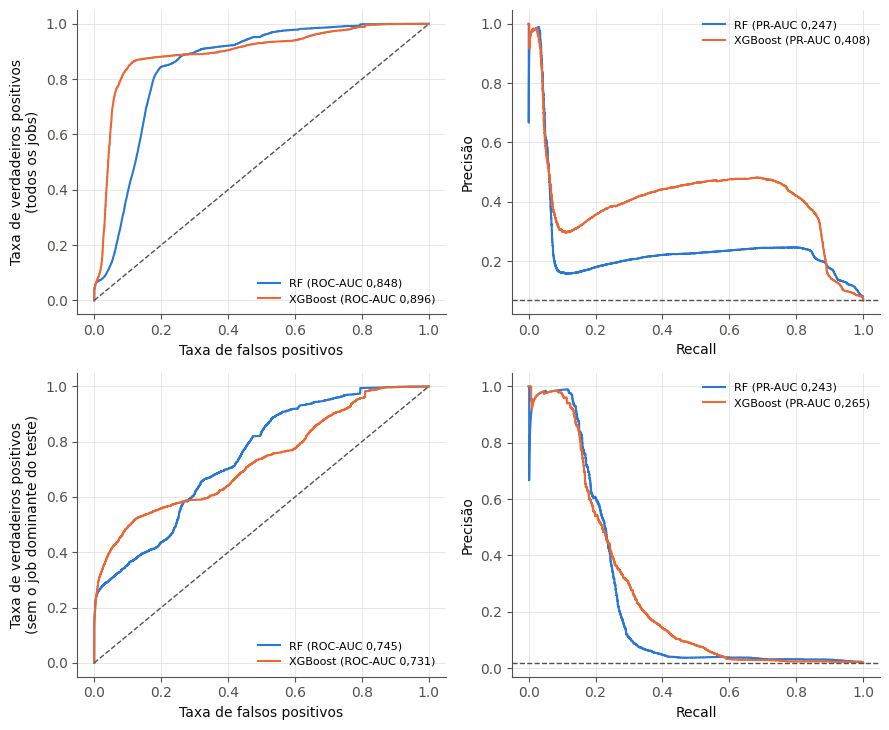

In [37]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7.4))
dt = base[TE]; y_te = dt.falha.to_numpy(); sem = ~dt.job_id.isin(EXCL['teste']).to_numpy()
cores = {'RF': AZUL, 'XGBoost': LARANJA}
for i, (rot, m) in enumerate((('todos os jobs', np.ones(len(dt), bool)), ('sem o job dominante do teste', sem))):
    for algo in ('RF', 'XGBoost'):
        p = PRB[('principal', algo)][m]; y = y_te[m]
        fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
        axs[i, 0].plot(fpr, tpr, color=cores[algo], label=f'{algo} (ROC-AUC {roc_auc_score(y, p):.3f})'.replace('.', ','))
        axs[i, 1].plot(rc, pr, color=cores[algo], label=f'{algo} (PR-AUC {average_precision_score(y, p):.3f})'.replace('.', ','))
    axs[i, 0].plot([0, 1], [0, 1], ls='--', lw=1, color=TXT2)
    axs[i, 1].axhline(y_te[m].mean(), ls='--', lw=1, color=TXT2)
    axs[i, 0].set_xlabel('Taxa de falsos positivos'); axs[i, 0].set_ylabel(f'Taxa de verdadeiros positivos\n({rot})')
    axs[i, 1].set_xlabel('Recall'); axs[i, 1].set_ylabel('Precisão')
    for ax in axs[i]: ax.legend(frameon=False, fontsize=8, loc='lower right' if ax is axs[i, 0] else 'upper right')
fig.tight_layout()
fig.savefig(f'{FIG}/classificacao_curvas_teste.png', dpi=200)
plt.show()


## 10. Matrizes de confusão no teste
Modelo principal, com o limiar escolhido na validação, com todos os jobs e sem o job dominante do teste. Os percentuais são normalizados pelo total de tarefas de cada recorte (os quatro campos somam 100%); as contagens absolutas (VN, FP, FN, VP) ficam em `saida/classificacao_metricas.csv`.

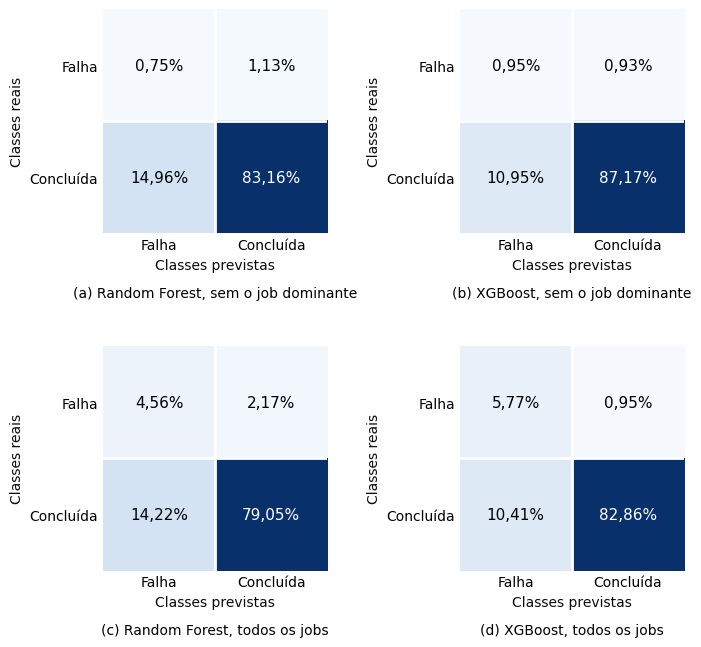

In [38]:
from matplotlib.colors import Normalize

teste = res[(res.conjunto == 'teste') & (res.variante == 'principal')]
paineis = [('Random Forest', 'RF', 'sem os jobs dominantes', 'sem o job dominante'),
           ('XGBoost', 'XGBoost', 'sem os jobs dominantes', 'sem o job dominante'),
           ('Random Forest', 'RF', 'todos os jobs', 'todos os jobs'),
           ('XGBoost', 'XGBoost', 'todos os jobs', 'todos os jobs')]
fig, axs = plt.subplots(2, 2, figsize=(7.2, 6.6))
for ax, letra, (nome, algo, recorte, rotulo) in zip(axs.ravel(), 'abcd', paineis):
    r = teste[(teste.algoritmo == algo) & (teste.recorte == recorte)].iloc[0]
    total = r.VN + r.FP + r.FN + r.VP
    m = np.array([[r.VP, r.FN], [r.FP, r.VN]]) / total * 100  # linhas: classe real (falha, concluída); colunas: prevista
    norm = Normalize(0, m.max())                              # escala de cor linear, proporcional ao percentual
    ax.imshow(m, cmap='Blues', norm=norm)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{m[i, j]:.2f}%'.replace('.', ','), ha='center', va='center', fontsize=11,
                    color='white' if norm(m[i, j]) > 0.55 else 'black')
    ax.axhline(0.5, color='white', lw=2); ax.axvline(0.5, color='white', lw=2)   # separa os quadrantes
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Falha', 'Concluída'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Falha', 'Concluída'])
    ax.set_xlabel('Classes previstas'); ax.set_ylabel('Classes reais')
    ax.set_title(f'({letra}) {nome}, {rotulo}', fontsize=10, y=-0.32)
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.tick_params(length=0, colors='black')
fig.tight_layout(h_pad=3.2, w_pad=2.5)
fig.savefig(f'{FIG}/classificacao_matriz_confusao.png', dpi=200, facecolor='white')
plt.show()


## 11. Explicabilidade com valores SHAP
Aplicada só ao modelo de melhor desempenho na validação (modelo principal, ajustado nos dias 1 a 23), em uma amostra aleatória de tarefas do teste, com todos os jobs e sem o job dominante. Os valores se referem à classe de falha; as escalas do Random Forest (probabilidade) e do XGBoost (log-odds) diferem.

SHAP no modelo XGBoost (maior PR-AUC ponderada por job na validação)
                     recorte           atributo  média |SHAP|
               todos os jobs         Prioridade        0.8864
               todos os jobs Memória solicitada        0.4622
               todos os jobs     CPU solicitada        0.3959
               todos os jobs     Memória máxima        0.3213
               todos os jobs          CPU média        0.2802
               todos os jobs   Disco solicitado        0.2736
               todos os jobs   Memória canônica        0.2338
               todos os jobs  Memória atribuída        0.2174
sem o job dominante do teste         Prioridade        0.8895
sem o job dominante do teste Memória solicitada        0.4605
sem o job dominante do teste     CPU solicitada        0.4222
sem o job dominante do teste     Memória máxima        0.3418
sem o job dominante do teste   Disco solicitado        0.2795
sem o job dominante do teste          CPU média        0.2718
s

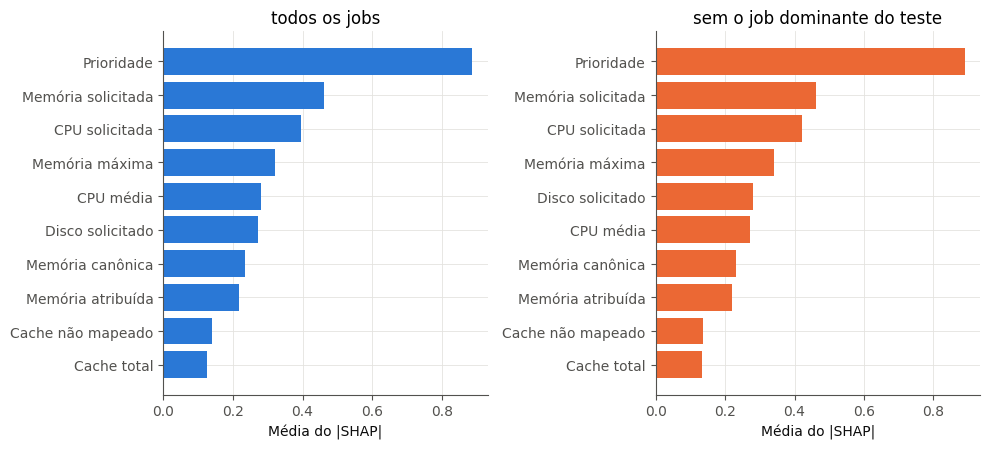

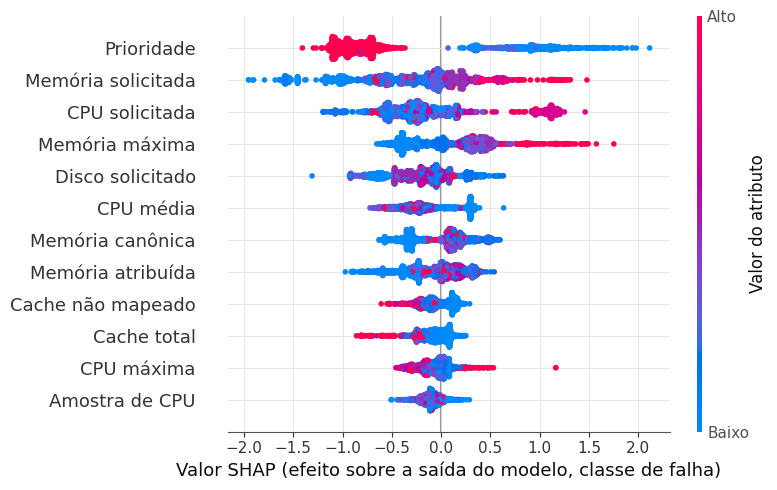

In [39]:
# Modelo de melhor desempenho entre os principais, escolhido na validação (não no teste)
algo_shap = max(('RF', 'XGBoost'), key=lambda a: SCORE_VAL[('principal', a)])
pre, modelo, lim_shap, colunas = MODELOS[('principal', algo_shap)]
print('SHAP no modelo', algo_shap, '(maior PR-AUC ponderada por job na validação)')

rng = np.random.RandomState(SEED)
dt = base[TE]
amostras = {'todos os jobs': dt, 'sem o job dominante do teste': dt[dt.job_id != DOM['teste']]}
def rotulo(c): return NOMES.get(c, c)

expl = shap.TreeExplainer(modelo)
saida, valores = [], {}
for rot, d in amostras.items():
    d = d.iloc[rng.choice(len(d), size=min(AMOSTRA_SHAP, len(d)), replace=False)]
    X = pre.transform(d)
    sv = expl(X)
    v = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values          # classe de falha
    valores[rot] = (X, v)
    imp = pd.Series(np.abs(v).mean(axis=0), index=X.columns).sort_values(ascending=False)
    saida.append(pd.DataFrame({'recorte': rot, 'atributo': [rotulo(c) for c in imp.index], 'média |SHAP|': imp.values}))
shap_tab = pd.concat(saida, ignore_index=True)
shap_tab.round(5).to_csv(f'{SAIDA}/classificacao_shap.csv', index=False)
print(shap_tab.groupby('recorte').head(8).round(4).to_string(index=False))

# Figura 1: importância média, lado a lado
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6), sharex=False)
for ax, (rot, (X, v)) in zip(axs, valores.items()):
    imp = pd.Series(np.abs(v).mean(axis=0), index=[rotulo(c) for c in X.columns]).sort_values().tail(10)
    ax.barh(imp.index, imp.values, color=AZUL if rot == 'todos os jobs' else LARANJA)
    ax.set_title(rot); ax.set_xlabel('Média do |SHAP|')
fig.tight_layout()
fig.savefig(f'{FIG}/shap_importancia.png', dpi=200)
plt.show()

# Figura 2: resumo (beeswarm) sem o job dominante
X, v = valores['sem o job dominante do teste']
Xr = X.rename(columns=rotulo)
plt.figure()
shap.summary_plot(v, Xr, show=False, max_display=12, plot_size=(8, 5))
ax = plt.gca(); ax.set_xlabel('Valor SHAP (efeito sobre a saída do modelo, classe de falha)')
try:
    cb = plt.gcf().axes[-1]; cb.set_ylabel('Valor do atributo'); cb.set_yticks(cb.get_ylim()); cb.set_yticklabels(['Baixo', 'Alto'])
except Exception:
    pass
plt.tight_layout()
plt.savefig(f'{FIG}/shap_resumo.png', dpi=200, bbox_inches='tight')
plt.show()


## 12. Gravação dos resultados

In [40]:
chaves = list(PRB)
prob = base.loc[TE, KEY + ['falha', 'dia_job']].reset_index(drop=True)
for (variante, algo) in chaves:
    prob[f'{variante} | {algo}'] = PRB[(variante, algo)]
prob.to_parquet(f'{SAIDA}/classificacao_predicoes_teste.parquet', index=False)
pd.DataFrame([{'algoritmo': a, **MELHOR[a]} for a in MELHOR]).to_csv(f'{SAIDA}/classificacao_hiperparametros.csv', index=False)
print('gravado em', SAIDA)


gravado em /content/drive/MyDrive/artigo_predicao/saida
